# The temperature of Prague from Landsat 8: Planck's law in practice

[![Open in Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OpenSkyLab-space/notebooks/blob/main/blackbody_radiation_en.ipynb)

**OpenSkyLab · notebook for the visual** [Blackbody radiation](https://openskylab.space/edu_viz_blackbody_radiation.html) · [česká verze](blackbody_radiation_cs.ipynb)

The visual shows Planck's law, Wien's shift, the fourth power of the Stefan–Boltzmann law and the role of emissivity. Here you apply the same formulas to a real Landsat 8 thermal image from the heat wave of 26 June 2019 and turn digital numbers into the surface temperature of Prague.

**Goal:** convert the Landsat 8 thermal band from DN to radiance and brightness temperature, correct it for emissivity, estimate the error from a wrong emissivity and from sky reflection, and show why satellites look for small fires at 3.9 µm.

**Data:** Landsat 8 OLI/TIRS, Collection 1 Level-1, scene `LC08_L1TP_191025_20190626_20190705_01_T1` (26 June 2019, 09:51 UTC, cloud cover 0.1 %), bands B4, B5 and B10 and the MTL file with calibration constants from the Google Cloud public archive. Only a 16 × 16 km window around central Prague is read (about 3 MB).

**Tasks:** five. Write your answers in the *Your answer* cells below the tasks. Lines marked `# ◀ parameter` are meant to be changed; run the cell again with Shift + Enter.

**Time:** about 45 min. You need a Google account (Colab); nothing is installed on your computer. Run the cells in order from top to bottom.

## 1. Setup

In [1]:
%pip install -q rasterio

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np, requests
import matplotlib.pyplot as plt
import rasterio
from rasterio.windows import from_bounds
from pyproj import Transformer
from scipy.constants import h, c, k, sigma

def planck(lam_um, T):
    """Blackbody spectral radiance in W·m⁻²·sr⁻¹·µm⁻¹ for wavelength in µm and temperature in K."""
    lam = np.asarray(lam_um) * 1e-6
    return 2 * h * c**2 / lam**5 / np.expm1(h * c / (lam * k * T)) * 1e-6

def planck_inv(lam_um, L):
    """Brightness temperature (K): the temperature of a blackbody with radiance L at wavelength lam_um."""
    lam = lam_um * 1e-6
    return h * c / (lam * k) / np.log1p(2 * h * c**2 / lam**5 / (np.asarray(L) * 1e6))

## 2. Planck's law, Wien and the fourth power

  300 K: peak   9.66 µm, exitance      457.1 W/m² (σT⁴ =      459.3), radiance at 10.9 µm     9.62 W·m⁻²·sr⁻¹·µm⁻¹
  600 K: peak   4.83 µm, exitance       7344 W/m² (σT⁴ =       7349), radiance at 10.9 µm     96.5 W·m⁻²·sr⁻¹·µm⁻¹
  900 K: peak   3.22 µm, exitance   3.72e+04 W/m² (σT⁴ =   3.72e+04), radiance at 10.9 µm      232 W·m⁻²·sr⁻¹·µm⁻¹
 5772 K: peak   0.50 µm, exitance  6.294e+07 W/m² (σT⁴ =  6.294e+07), radiance at 10.9 µm 3.01e+03 W·m⁻²·sr⁻¹·µm⁻¹


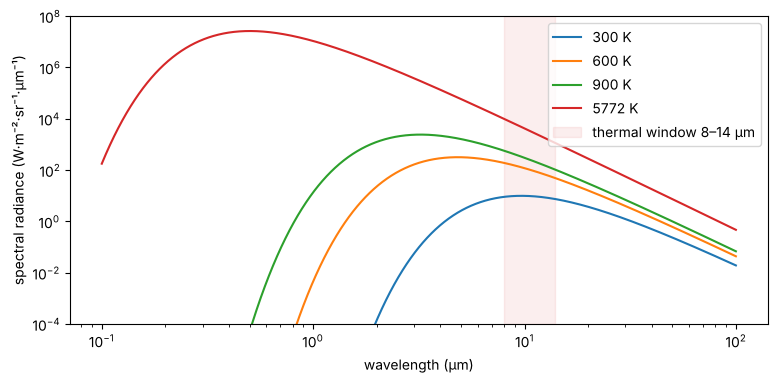

In [3]:
T_list = [300, 600, 900, 5772]      # ◀ parameter: temperatures in K (landscape, stove, fire, solar surface)
lam = np.logspace(-1, 2, 2000)      # 0.1 to 100 µm
fig, ax = plt.subplots(figsize=(9, 4))
for T in T_list:
    L = planck(lam, T)
    ax.loglog(lam, L, label=f"{T} K")
    lmax = 2897.77 / T                                   # Wien's displacement law, µm
    M = np.trapezoid(L, lam) * np.pi                     # radiance → radiant exitance (W·m⁻²)
    print(f"{T:5d} K: peak {lmax:6.2f} µm, exitance {M:10.4g} W/m² (σT⁴ = {sigma * T**4:10.4g}), "
          f"radiance at 10.9 µm {planck(10.9, T):8.3g} W·m⁻²·sr⁻¹·µm⁻¹")
ax.axvspan(8, 14, color="tab:red", alpha=0.08, label="thermal window 8–14 µm")
ax.set(xlabel="wavelength (µm)", ylabel="spectral radiance (W·m⁻²·sr⁻¹·µm⁻¹)", ylim=(1e-4, 1e8))
ax.legend(); plt.show()

> **✏️ Task 1.** How many times do the total exitance and the radiance at 10.9 µm increase when you double the temperature from 300 to 600 K? Why do the two numbers differ? Also compute how many per cent more asphalt at 45 °C emits than grass at 25 °C.

*Your answer:* 

## 3. A real scene: from DN to brightness temperature

Band B10 (10.6–11.2 µm) stores digital numbers (DN). The MTL file holds the linear conversion to radiance, L = M · DN + A, and the constants K1, K2 that turn radiance into brightness temperature, T = K2 / ln(K1 / L + 1). It is Planck's law simplified for one band.

In [4]:
SCENE = "LC08_L1TP_191025_20190626_20190705_01_T1"
BASE = f"https://storage.googleapis.com/gcp-public-data-landsat/LC08/01/191/025/{SCENE}/{SCENE}"
mtl = dict(l.strip().split(" = ") for l in requests.get(BASE + "_MTL.txt", timeout=60).text.splitlines() if " = " in l)
num = lambda key: float(mtl[key])

lon, lat, half = 14.42, 50.08, 8000      # ◀ parameter: window centre (°) and half-width (m)

def read_band(b):
    with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR", GDAL_HTTP_MAX_RETRY=5, GDAL_HTTP_RETRY_DELAY=2):
        with rasterio.open(f"/vsicurl/{BASE}_B{b}.TIF") as r:
            x, y = Transformer.from_crs(4326, r.crs, always_xy=True).transform(lon, lat)
            return r.read(1, window=from_bounds(x - half, y - half, x + half, y + half, r.transform)).astype(float)

dn10 = read_band(10)
L10 = num("RADIANCE_MULT_BAND_10") * dn10 + num("RADIANCE_ADD_BAND_10")
BT = num("K2_CONSTANT_BAND_10") / np.log(num("K1_CONSTANT_BAND_10") / L10 + 1)
print("date and time:", mtl["DATE_ACQUIRED"], mtl["SCENE_CENTER_TIME"].strip('"'), "| sun elevation", mtl["SUN_ELEVATION"], "°")
print(f"DN {dn10.min():.0f}–{dn10.max():.0f} → radiance {L10.min():.2f}–{L10.max():.2f} W·m⁻²·sr⁻¹·µm⁻¹ → "
      f"brightness temperature {BT.min() - 273.15:.1f} to {BT.max() - 273.15:.1f} °C")
print(f"check with Planck at 10.9 µm: {planck_inv(10.9, np.median(L10)) - 273.15:.1f} °C vs. K1/K2: {np.median(BT) - 273.15:.1f} °C")

date and time: 2019-06-26 09:50:52.4753079Z | sun elevation 59.75814548 °
DN 26862–36973 → radiance 9.08–12.46 W·m⁻²·sr⁻¹·µm⁻¹ → brightness temperature 23.1 to 45.5 °C
check with Planck at 10.9 µm: 33.4 °C vs. K1/K2: 33.6 °C


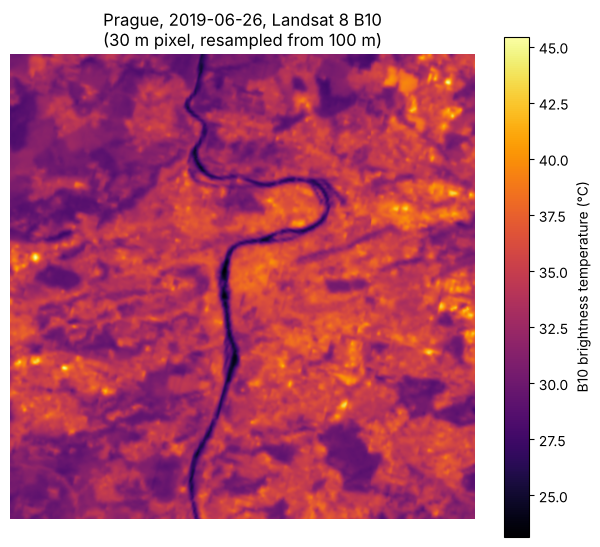

In [5]:
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(BT - 273.15, cmap="inferno")
fig.colorbar(im, ax=ax, label="B10 brightness temperature (°C)")
ax.set_title(f"Prague, {mtl['DATE_ACQUIRED']}, Landsat 8 B10\n(30 m pixel, resampled from 100 m)")
ax.axis("off"); plt.show()

> **✏️ Task 2.** Find the Vltava river, large parks or forests (Stromovka, Hvězda, Krč) and built-up areas with large halls on the map. What brightness temperatures do they have? Why is the difference between the river and hall roofs so large around noon? Why is brightness temperature not the same as surface temperature?

*Your answer:* 

## 4. Emissivity

Real surfaces emit less than a blackbody: L = ε · B(T). We estimate emissivity from NDVI with the threshold method (Sobrino et al. 2004): water 0.991, bare surface 0.97, full vegetation 0.99, in between according to the vegetation fraction. Sky reflection and the atmosphere are ignored for now.

emissivity 0.970–0.991; correction LST − BT: median 0.55 K, range 0.41 to 2.13 K


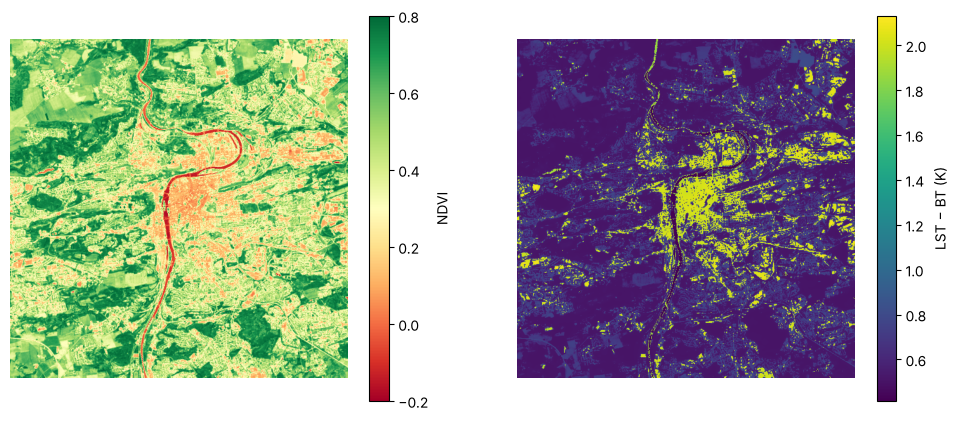

In [6]:
sun = np.sin(np.radians(num("SUN_ELEVATION")))
refl = lambda b: (num(f"REFLECTANCE_MULT_BAND_{b}") * read_band(b) + num(f"REFLECTANCE_ADD_BAND_{b}")) / sun
red, nir = refl(4), refl(5)
ndvi = (nir - red) / (nir + red)

eps_soil, eps_veg, eps_water = 0.97, 0.99, 0.991     # ◀ parameter: emissivities
ndvi_s, ndvi_v = 0.2, 0.5
pv = np.clip((ndvi - ndvi_s) / (ndvi_v - ndvi_s), 0, 1) ** 2          # vegetation fraction of the pixel
# last term: cavity effect (multiple scattering between plants and soil), shape factor 0.55
eps = np.where(ndvi < 0, eps_water, np.where(ndvi < ndvi_s, eps_soil, eps_veg * pv + eps_soil * (1 - pv) + (1 - eps_soil) * (1 - pv) * 0.55 * eps_veg))
LST = planck_inv(10.9, L10 / eps)            # temperature of a body that would give the measured radiance with emissivity ε
d = LST - BT
print(f"emissivity {eps.min():.3f}–{eps.max():.3f}; correction LST − BT: median {np.median(d):.2f} K, range {d.min():.2f} to {d.max():.2f} K")
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
a = ax[0].imshow(ndvi, cmap="RdYlGn", vmin=-0.2, vmax=0.8); fig.colorbar(a, ax=ax[0], label="NDVI")
b = ax[1].imshow(d, cmap="viridis"); fig.colorbar(b, ax=ax[1], label="LST − BT (K)")
for x in ax: x.axis("off")
plt.show()

In [7]:
# how far off the sensor is when a surface has a different emissivity than assumed
T_true = 273.15 + 40          # ◀ parameter: true surface temperature in K
for eps_true in (0.98, 0.95, 0.92, 0.85):
    L = eps_true * planck(10.9, T_true)
    print(f"ε = {eps_true:.2f}: brightness temperature {planck_inv(10.9, L) - 273.15:5.1f} °C, error {planck_inv(10.9, L) - T_true:+5.2f} K")

ε = 0.98: brightness temperature  38.5 °C, error -1.47 K
ε = 0.95: brightness temperature  36.3 °C, error -3.71 K
ε = 0.92: brightness temperature  34.0 °C, error -5.99 K
ε = 0.85: brightness temperature  28.5 °C, error -11.47 K


> **✏️ Task 3.** Where is the emissivity correction largest and why? Roughly how many kelvin is the sensor off for each hundredth of emissivity? Change `eps_soil` to 0.95 (concrete, asphalt) and watch how the correction changes in built-up areas.

*Your answer:* 

## 5. Sky reflection

A surface with emissivity ε reflects 1 − ε of the longwave radiation coming from the sky. A clear sky is very cold at 10 µm, an overcast sky has roughly the temperature of the cloud base. The sensor receives L = ε · B(T) + (1 − ε) · B(T_sky).

In [8]:
T_surf = 273.15 + 27           # ◀ parameter: surface temperature
for name, eps_m in [("grass", 0.98), ("concrete", 0.92), ("oxidised sheet metal", 0.6), ("polished aluminium", 0.05)]:
    row = []
    for T_sky_c in (-40, -10, 10, 27):       # clear sky … low cloud … sky as warm as the surface
        L = eps_m * planck(10.9, T_surf) + (1 - eps_m) * planck(10.9, 273.15 + T_sky_c)
        row.append(f"{planck_inv(10.9, L) - 273.15:6.1f}")
    print(f"{name:20s} ε={eps_m:.2f}: brightness temperature with sky −40/−10/+10/+27 °C:", " ".join(row), "°C")

grass                ε=0.98: brightness temperature with sky −40/−10/+10/+27 °C:   26.0   26.4   26.7   27.0 °C
concrete             ε=0.92: brightness temperature with sky −40/−10/+10/+27 °C:   23.1   24.5   25.7   27.0 °C
oxidised sheet metal ε=0.60: brightness temperature with sky −40/−10/+10/+27 °C:    5.7   13.7   20.5   27.0 °C
polished aluminium   ε=0.05: brightness temperature with sky −40/−10/+10/+27 °C:  -34.9   -7.8   10.9   27.0 °C


> **✏️ Task 4.** Why does polished sheet metal under a clear sky look freezing cold in a thermal camera although it is at 27 °C? Why does emissivity not matter at all when the sky is as warm as the surface? In what weather would you therefore plan thermal imaging of roofs?

*Your answer:* 

## 6. A fire smaller than a pixel

A pixel is a mixture: a fraction p burns at the fire temperature, the rest has the background temperature. As background we take the median real brightness temperature of the Prague window and compare the 3.9 µm band (as on MODIS and VIIRS) with the 10.9 µm band.

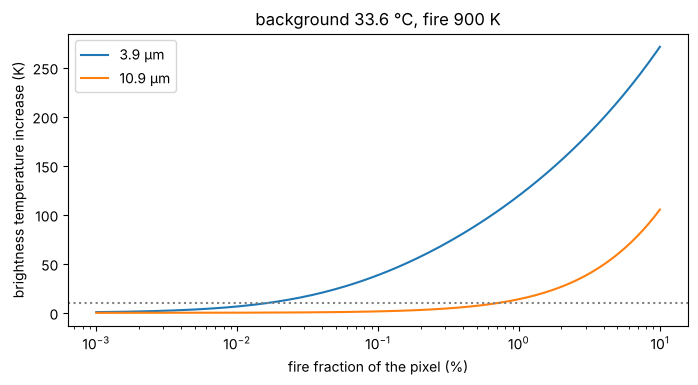

3.9 µm: a pixel 10 K warmer already at a fraction of 0.017 % = 168 m² of a 1 × 1 km pixel
10.9 µm: a pixel 10 K warmer already at a fraction of 0.715 % = 7149 m² of a 1 × 1 km pixel


In [9]:
T_fire = 900                     # ◀ parameter: fire temperature in K
T_bg = float(np.median(BT))
p = np.logspace(-5, -1, 200)     # fire fraction of the pixel
fig, ax = plt.subplots(figsize=(8, 3.8))
for lam_b in (3.9, 10.9):
    L = p * planck(lam_b, T_fire) + (1 - p) * planck(lam_b, T_bg)
    ax.semilogx(p * 100, planck_inv(lam_b, L) - T_bg, label=f"{lam_b} µm")
ax.axhline(10, color="gray", ls=":")
ax.set(xlabel="fire fraction of the pixel (%)", ylabel="brightness temperature increase (K)", title=f"background {T_bg - 273.15:.1f} °C, fire {T_fire} K")
ax.legend(); plt.show()
for lam_b in (3.9, 10.9):
    L = p * planck(lam_b, T_fire) + (1 - p) * planck(lam_b, T_bg)
    p10 = p[np.argmax(planck_inv(lam_b, L) - T_bg > 10)]
    print(f"{lam_b} µm: a pixel 10 K warmer already at a fraction of {p10 * 100:.3f} % = {p10 * 1e6:.0f} m² of a 1 × 1 km pixel")

> **✏️ Task 5.** At what fire fraction does the pixel warm by 10 K at 3.9 µm and at 10.9 µm? What area is that within a 1 × 1 km MODIS pixel? Explain the difference with Wien's law. Why do daytime algorithms also watch for reflected sunlight at 3.9 µm?

*Your answer:* 

---
### Data sources and references

- Landsat 8 OLI/TIRS Collection 1 Level-1, U.S. Geological Survey; Google Cloud public archive (`gcp-public-data-landsat`). USGS data are free of use restrictions (public domain), with attribution.
- DN to radiance and brightness temperature: USGS (2019). *Landsat 8 (L8) Data Users Handbook*, version 5.0, ch. 5.
- Emissivity from NDVI: Sobrino, J. A., Jiménez-Muñoz, J. C., Paolini, L. (2004). Land surface temperature retrieval from LANDSAT TM 5. *Remote Sensing of Environment* 90, 434–440. https://doi.org/10.1016/j.rse.2004.02.003
- Fire detection at 3.9 and 11 µm: Giglio, L., Schroeder, W., Justice, C. O. (2016). The collection 6 MODIS active fire detection algorithm and fire products. *Remote Sensing of Environment* 178, 31–41. https://doi.org/10.1016/j.rse.2016.02.054

### How to cite

OpenSkyLab (2026). The temperature of Prague from Landsat 8: Planck's law in practice [notebook, teaching resource], version 1.0. https://github.com/OpenSkyLab-space/notebooks/blob/main/blackbody_radiation_en.ipynb. Licence CC BY 4.0.

Notebook text and code: OpenSkyLab, licence [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Data are under their providers' licences (see above).

*This resource was developed by the OpenSkyLab team with the assistance of the generative AI Claude (Anthropic), used for drafting code and text. The authors are responsible for the content.*